# 딥러닝 응용 과제1 - 프로그래밍 A. 사전 학습된 분할 모델(YOLOv8-seg) 불러와 추론하기

교재 5.3절(`5_3.ipynb`, [프로그램 5-1]~[프로그램 5-5])에서는 **YOLOv8 객체 탐지(detection)** 모델을 불러와
경계 상자(bounding box)를 얻었습니다. 이 노트북에서는 같은 라이브러리(`ultralytics`)의
**YOLOv8 인스턴스 분할(instance segmentation)** 모델 `yolov8n-seg.pt`를 불러와
경계 상자에 더해 **물체 모양의 마스크(mask)** 까지 얻어 봅니다.

섹션 번호는 교재와 1:1로 대응됩니다.

| 이 노트북 | 교재 5_3.ipynb | 내용 |
| --- | --- | --- |
| [A-1] | [프로그램 5-1] | 사전 학습된 모델 불러오기 |
| [A-2] | [프로그램 5-2] | 테스트 이미지 불러오기 |
| [A-3] | [프로그램 5-3] | 모델 추론 실행하기 |
| [A-4] | [프로그램 5-4] | 결과를 텍스트로 확인하기 |
| [A-5] | [프로그램 5-5] | 결과를 시각화하기 |
| [A-6] | (추가) | 설정값을 바꾸며 결과 관찰하기 |

**과제 규칙**
- 이 노트북에는 `your code here`로 표시된 빈칸이 **8곳** 있습니다. 힌트 주석을 읽고 빈칸을 채우세요. 빈칸 밖의 코드는 고치지 않아도 됩니다.
- 모두 채우고 **런타임 → 모두 실행** 했을 때 저장소 `preview/` 폴더의 그림(프로그래밍A_YOLO_page*.jpg)과 같은 형태의 결과가 나와야 합니다.
- 교재 5_3.ipynb의 같은 번호 [프로그램]을 옆에 두고 보면 대부분의 빈칸을 채울 수 있습니다.

**실행 방법**
1. 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 를 고르세요 (CPU로도 돌아가지만 느립니다).
2. 바로 아래 **실험 설정** 셀의 값을 확인하고 **런타임 → 모두 실행**.
3. 서술형 과제를 할 때는 설정 셀의 값만 바꾼 뒤 다시 **모두 실행** 하고 결과를 비교하세요.

In [1]:
# ── 실험 설정 (이 셀의 값을 바꿔 가며 실험하세요) ─────────────────────────
MODEL_NAME = "yolov8n-seg.pt"   # 사전 학습된 모델. 예: yolov8n.pt (교재), yolov8n-seg.pt, yolov8s-seg.pt, yolov8m-seg.pt
CONF       = 0.25               # 신뢰도(confidence) 임계값: 이 값보다 점수가 낮은 탐지는 버림 (0~1)
IOU        = 0.7                # NMS(비최대 억제)의 IoU 임계값: 겹치는 상자를 얼마나 허용할지 (0~1)
IMGSZ      = 640                # 추론 입력 크기(한 변, 32의 배수). 예: 320, 640, 1280

IMAGE_URL  = "https://ultralytics.com/images/bus.jpg"   # 테스트 이미지 주소 (COCO 스타일 사진)
MY_PHOTO   = None               # 내 사진 경로를 쓰면 그 사진을 사용. None이면 IMAGE_URL 사용

# [A-6]에서 비교할 값들
CONF_LIST  = [0.05, 0.25, 0.5, 0.8]
IMGSZ_LIST = [320, 640, 1280]
MODEL_LIST = ["yolov8n-seg.pt", "yolov8s-seg.pt", "yolov8m-seg.pt"]

## [A-1] 사전 학습된 YOLOv8 분할 모델 불러오기 (교재 [프로그램 5-1] 대응)

교재에서는 `YOLO("yolov8n.pt")`로 **탐지** 모델을 불러왔습니다. 여기서는 파일 이름 뒤에 `-seg`가 붙은
**분할** 모델을 불러옵니다. 둘 다 COCO 데이터셋(80개 클래스)으로 미리 학습되어 있어서
우리는 학습 없이 바로 추론만 하면 됩니다.

In [2]:
# YOLO 설치 (Colab에는 기본 설치되어 있지 않음)
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)

import torch
from ultralytics import YOLO

# 장치 선택
# ───────────── your code here ─────────────
# 교재 [프로그램 5-1]처럼 GPU가 있으면 "cuda", 없으면 "cpu"를 쓰는 device를 만드세요
device = "cuda" if torch.cuda.is_available() else "cpu"
# ─────────────────────────────────────────
print("Using device:", device)

# 사전 학습된 모델 로드 (처음 한 번은 가중치 파일을 내려받음)
# ───────────── your code here ─────────────
# 설정 셀의 MODEL_NAME으로 사전 학습된 YOLO 모델을 불러와 model에 저장하세요 (교재 [프로그램 5-1])
model = YOLO(MODEL_NAME)
# ─────────────────────────────────────────

n_params = sum(p.numel() for p in model.model.parameters())
print(f"모델: {MODEL_NAME} | 작업(task): {model.task} | 파라미터 수: {n_params:,}")
print(f"클래스 수: {len(model.names)}개 → 예) {[model.names[i] for i in range(5)]} ...")

Using device: cuda
모델: yolov8n-seg.pt | 작업(task): segment | 파라미터 수: 3,409,968
클래스 수: 80개 → 예) ['person', 'bicycle', 'car', 'motorcycle', 'airplane'] ...


## [A-2] 테스트 이미지 불러오기 (교재 [프로그램 5-2] 대응)

교재와 같이 인터넷에서 사진 한 장을 내려받아 PIL 이미지로 엽니다.
`MY_PHOTO`에 내 사진 경로를 적으면 그 사진을 씁니다 (Colab 왼쪽 **파일** 탭에서 업로드 → 경로 복사).

내려받은 이미지: https://ultralytics.com/images/bus.jpg
이미지 크기 (W, H): (810, 1080)


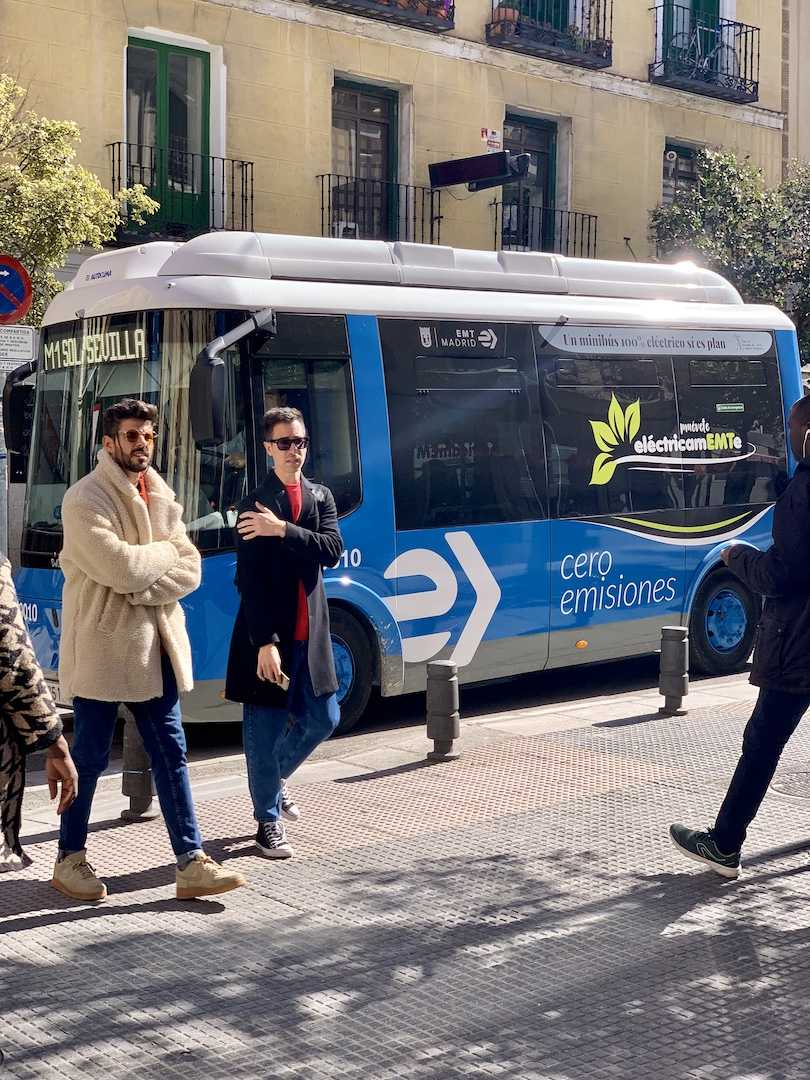

In [3]:
from PIL import Image
from io import BytesIO
import requests

if MY_PHOTO is not None:
    img = Image.open(MY_PHOTO).convert("RGB")
    print("내 사진 사용:", MY_PHOTO)
else:
    try:
        # ───────────── your code here ─────────────
        # IMAGE_URL에서 이미지를 내려받아 RGB PIL 이미지 img를 만드세요
        # 교재 [프로그램 5-2]: requests.get → raise_for_status → BytesIO → Image.open → convert("RGB")
        response = requests.get(IMAGE_URL, timeout=10)
        response.raise_for_status()
        img = Image.open(BytesIO(response.content)).convert("RGB")
        # ─────────────────────────────────────────
        print("내려받은 이미지:", IMAGE_URL)
    except Exception as e:                           # 인터넷 문제 시 ultralytics에 들어 있는 예시 사진 사용
        from ultralytics.utils import ASSETS
        img = Image.open(ASSETS / "bus.jpg").convert("RGB")
        print(f"다운로드 실패({e.__class__.__name__}) → 예시 사진 bus.jpg 사용")

print("이미지 크기 (W, H):", img.size)
img

## [A-3] 모델 추론 실행하기 (교재 [프로그램 5-3] 대응)

`predict()`에 설정 셀의 `conf`, `iou`, `imgsz`를 넘깁니다. 교재에서는 기본값(conf=0.25, iou=0.7, imgsz=640)을
그대로 썼습니다. 모델은 입력 이미지를 `imgsz`에 맞게 줄이거나 키운 뒤 추론하고, 결과 좌표는 원래 이미지 크기로 되돌려 줍니다.

In [4]:
# ───────────── your code here ─────────────
# img에 대해 model.predict(...)를 실행해 results에 저장하세요
# 설정 셀의 CONF, IOU, IMGSZ, device를 인자로 넘기고 verbose=False로 두세요 (교재 [프로그램 5-3])
results = model.predict(img, conf=CONF, iou=IOU, imgsz=IMGSZ, device=device, verbose=False)
# ─────────────────────────────────────────

r = results[0]
print("탐지된 물체 수:", len(r.boxes))
print("모델에 들어간 입력 크기 (H, W):", tuple(r.masks.data.shape[-2:]) if r.masks is not None else "마스크 없음")
print("처리 시간(ms):", {k: round(v, 1) for k, v in r.speed.items()})

탐지된 물체 수: 6
모델에 들어간 입력 크기 (H, W): (640, 480)
처리 시간(ms): {'preprocess': 66.6, 'inference': 20.5, 'postprocess': 48.3}


## [A-4] 탐지 결과를 텍스트로 확인하기 (교재 [프로그램 5-4] 대응)

교재의 `box.cls`, `box.conf`, `box.xyxy`에 더해 분할 모델은 `r.masks`를 돌려줍니다.
`r.masks.data`는 (물체 수, H, W) 모양의 0/1 텐서입니다. 마스크의 1인 픽셀 비율로 물체가 화면에서
차지하는 면적을 어림할 수 있습니다.

In [5]:
for r in results:
    masks = r.masks.data if r.masks is not None else None
    for i, box in enumerate(r.boxes):
        # ───────────── your code here ─────────────
        # 교재 [프로그램 5-4]처럼 box에서 클래스 번호 cls_id(int), 점수 score(float), 좌표 x1, y1, x2, y2를 꺼내세요
        # 클래스 이름은 model.names[cls_id]로 얻어 name에 저장하세요
        cls_id = int(box.cls[0])
        score = float(box.conf[0])
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        name = model.names[cls_id]
        # ─────────────────────────────────────────
        # ───────────── your code here ─────────────
        # masks[i]에서 값이 1인 픽셀의 비율(%)을 구해 area에 저장하세요. masks가 None이면 float("nan")
        # 힌트: 0/1 텐서의 평균이 곧 비율입니다 (.float().mean())
        area = masks[i].float().mean().item() * 100 if masks is not None else float("nan")
        # ─────────────────────────────────────────
        print(f"class={cls_id:2d} ({name:>12s}), score={score:.3f}, "
              f"box=({x1:.1f},{y1:.1f})-({x2:.1f},{y2:.1f}), mask area={area:.1f}%")

class= 0 (      person), score=0.878, box=(670.2,388.7)-(809.5,877.1), mask area=2.5%
class= 0 (      person), score=0.860, box=(48.5,396.2)-(242.4,904.4), mask area=5.9%
class= 0 (      person), score=0.841, box=(222.5,407.8)-(344.2,861.9), mask area=3.9%
class= 5 (         bus), score=0.838, box=(2.9,228.0)-(800.5,722.0), mask area=29.7%
class= 0 (      person), score=0.411, box=(0.0,551.6)-(77.8,875.5), mask area=1.4%
class=36 (  skateboard), score=0.392, box=(669.0,822.9)-(810.0,882.2), mask area=0.3%


## [A-5] 결과를 시각화하기 (교재 [프로그램 5-5] 대응)

교재는 `results[0].show()` 한 줄로 그렸습니다. 여기서는 `plot()`이 돌려주는 이미지를 matplotlib로 나란히 그려
**상자만** 그린 것과 **상자 + 마스크**를 비교합니다. (`plot()`은 OpenCV 방식의 BGR 배열을 주므로 RGB로 뒤집어 그립니다.)

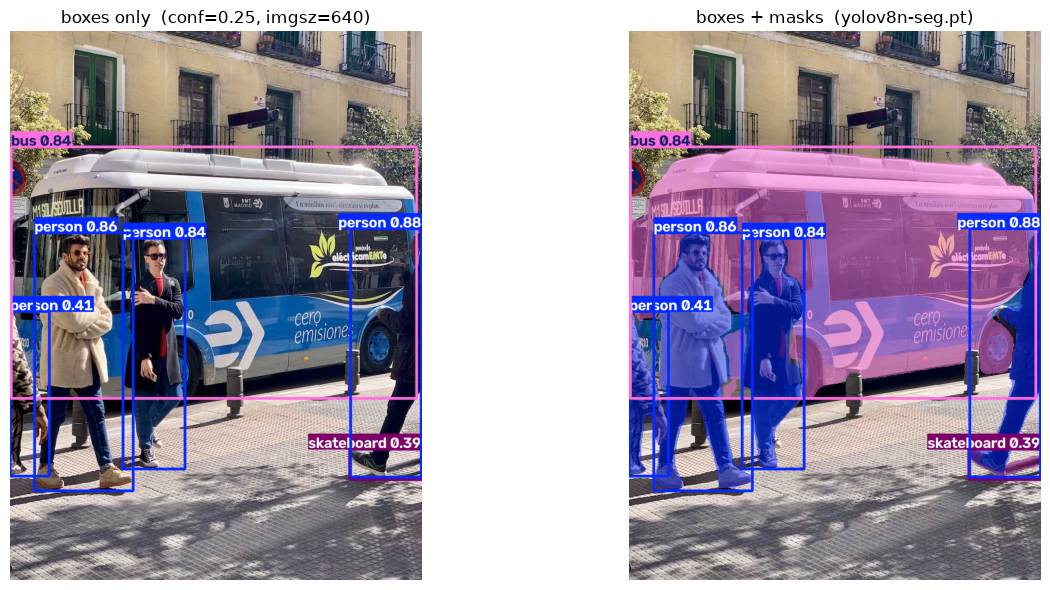

In [6]:
import matplotlib.pyplot as plt

r = results[0]
r.save("detected.jpg")                       # 탐지 결과 이미지 저장 (교재와 동일)

boxes_only = r.plot(masks=False)[..., ::-1]  # BGR → RGB
with_masks = r.plot()[..., ::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(boxes_only); axes[0].set_title(f"boxes only  (conf={CONF}, imgsz={IMGSZ})"); axes[0].axis("off")
axes[1].imshow(with_masks); axes[1].set_title(f"boxes + masks  ({MODEL_NAME})"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## [A-6] 설정값을 바꾸며 결과 관찰하기 (추가)

아래 함수는 **같은 사진**에 대해 모델·`conf`·`imgsz`만 바꿔 추론하고, 탐지 개수와 추론 시간을 표로 모읍니다.
표를 보고 다음을 관찰하세요.

- `conf`를 낮추면/높이면 탐지 개수가 어떻게 변하는가? 새로 생기거나 사라지는 물체는 어떤 것인가?
- `imgsz`를 320 → 1280으로 키우면 작은 물체 탐지와 추론 시간이 어떻게 변하는가?
- 모델을 n → s → m으로 키우면 파라미터 수, 시간, 점수가 어떻게 변하는가?

(서술 과제의 문제는 이 표와 [A-5]의 그림을 근거로 답하면 됩니다.)

In [7]:
import time
from collections import Counter
import pandas as pd

_model_cache = {}

def run_experiment(model_name=MODEL_NAME, conf=CONF, iou=IOU, imgsz=IMGSZ, image=None):
    image = img if image is None else image
    if model_name not in _model_cache:
        _model_cache[model_name] = YOLO(model_name)
    m = _model_cache[model_name]
    m.predict(image, imgsz=imgsz, device=device, verbose=False)              # 준비 운동(첫 실행은 느림)
    # ───────────── your code here ─────────────
    # 모델 m으로 image를 conf, iou, imgsz 인자로 추론하고 첫 번째 결과를 r에 저장하세요 ([A-3]과 같은 호출, 결과 리스트의 [0])
    r = m.predict(image, conf=conf, iou=iou, imgsz=imgsz, device=device, verbose=False)[0]
    # ─────────────────────────────────────────
    names = [m.names[int(c)] for c in r.boxes.cls]
    return {"model": model_name, "conf": conf, "iou": iou, "imgsz": imgsz,
            "params": sum(p.numel() for p in m.model.parameters()),
            "n_det": len(r.boxes), "infer_ms": round(r.speed["inference"], 1),
            "mean_score": round(float(r.boxes.conf.mean()), 3) if len(r.boxes) else None,
            "classes": dict(Counter(names))}

rows = []
# ───────────── your code here ─────────────
# 실험 A: CONF_LIST의 값마다 run_experiment(conf=...)를 호출해 rows에 추가하세요
# 실험 B: IMGSZ_LIST의 값마다 run_experiment(imgsz=...)
# 실험 C: MODEL_LIST의 값마다 run_experiment(model_name=...)
# 한 번에 한 가지 값만 바꾸고 나머지는 기본값을 씁니다
for c in CONF_LIST:
    rows.append(run_experiment(conf=c))
for s in IMGSZ_LIST:
    rows.append(run_experiment(imgsz=s))
for name in MODEL_LIST:
    rows.append(run_experiment(model_name=name))
# ─────────────────────────────────────────

df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 80)
df

,model,conf,iou,imgsz,params,n_det,infer_ms,mean_score,classes
0,yolov8n-seg.pt,0.05,0.7,640,3409968,9,19.2,0.506,"{'person': 5, 'bus': 1, 'skateboard': 1, 'umbrella': 1, 'stop sign': 1}"
1,yolov8n-seg.pt,0.25,0.7,640,3409968,6,23.8,0.704,"{'person': 4, 'bus': 1, 'skateboard': 1}"
2,yolov8n-seg.pt,0.50,0.7,640,3409968,4,32.1,0.854,"{'person': 3, 'bus': 1}"
3,yolov8n-seg.pt,0.80,0.7,640,3409968,4,29.3,0.854,"{'person': 3, 'bus': 1}"
4,yolov8n-seg.pt,0.25,0.7,320,3409968,4,21.1,0.776,"{'bus': 1, 'person': 3}"
5,yolov8n-seg.pt,0.25,0.7,640,3409968,6,20.2,0.704,"{'person': 4, 'bus': 1, 'skateboard': 1}"
6,yolov8n-seg.pt,0.25,0.7,1280,3409968,6,27.3,0.579,"{'person': 4, 'horse': 1, 'bus': 1}"
7,yolov8n-seg.pt,0.25,0.7,640,3409968,6,21.5,0.704,"{'person': 4, 'bus': 1, 'skateboard': 1}"
8,yolov8s-seg.pt,0.25,0.7,640,11821056,6,23.8,0.772,"{'person': 4, 'bus': 1, 'tie': 1}"
9,yolov8m-seg.pt,0.25,0.7,640,27285968,6,23.6,0.754,"{'person': 4, 'bus': 1, 'tie': 1}"


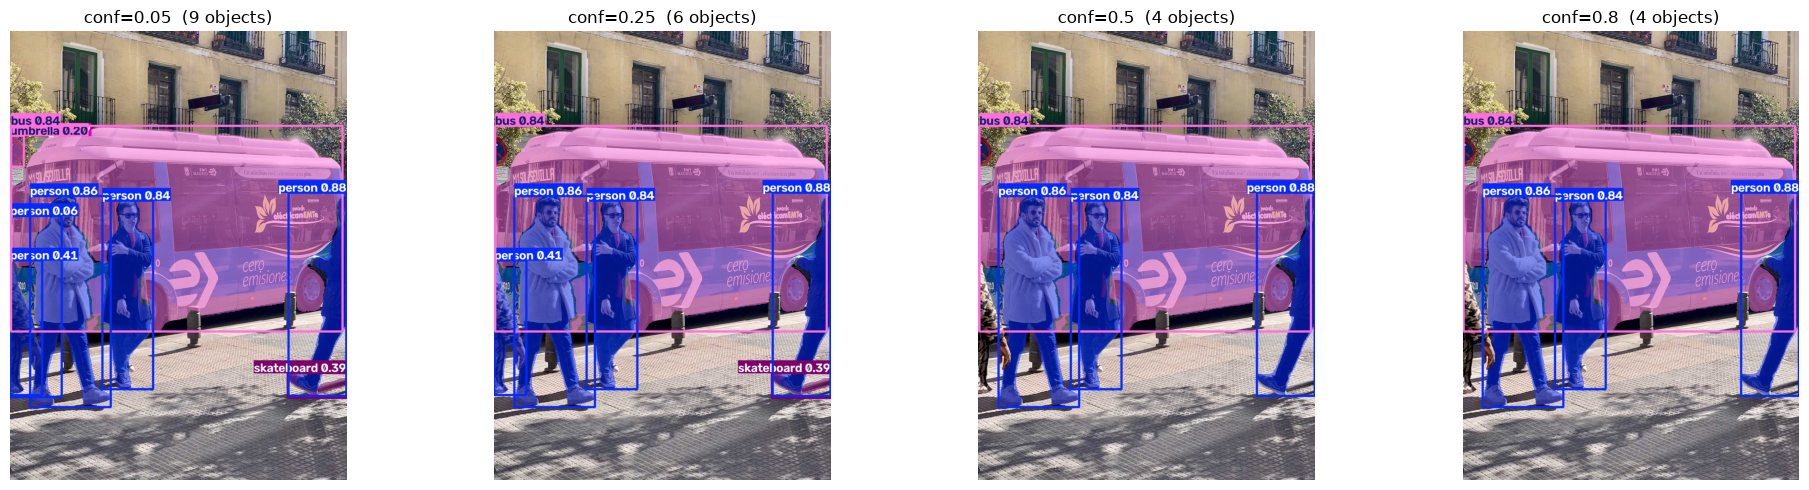

In [8]:
# 실험 A의 결과를 그림으로: conf 값에 따라 그려지는 상자가 어떻게 달라지는지 확인
fig, axes = plt.subplots(1, len(CONF_LIST), figsize=(5 * len(CONF_LIST), 5))
for ax, c in zip(axes, CONF_LIST):
    rr = model.predict(img, conf=c, iou=IOU, imgsz=IMGSZ, device=device, verbose=False)[0]
    ax.imshow(rr.plot()[..., ::-1]); ax.set_title(f"conf={c}  ({len(rr.boxes)} objects)"); ax.axis("off")
plt.tight_layout(); plt.show()